# Palkkatulot koulutusasteen ja koulutusalan mukaan vuonna 2024

Vera Jalava

2520405


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
palkkatiedot = pd.read_excel("t8_tilastokeskus.xlsx")
palkkatiedot.head()

,Koulutusaste,Miehet_euroa_kk,Naiset_euroa_kk
0,Toinen aste,3463,2860
1,Erikoisammattikouluaste,4213,3277
2,Alin korkea-aste,4500,3477
3,Alempi korkeakouluaste,4423,3448
4,Ylempi korkeakouluaste,5496,4547


Tarkastelen seuraavaksi aineiston rakennetta ja sarakkeiden tietoja

In [3]:
palkkatiedot.info()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Koulutusaste     7 non-null      str  
 1   Miehet_euroa_kk  7 non-null      int64
 2   Naiset_euroa_kk  7 non-null      int64
dtypes: int64(2), str(1)
memory usage: 300.0 bytes


1. Mediaanitulojen vertailu eri koulutusasteilla vuonna 2024

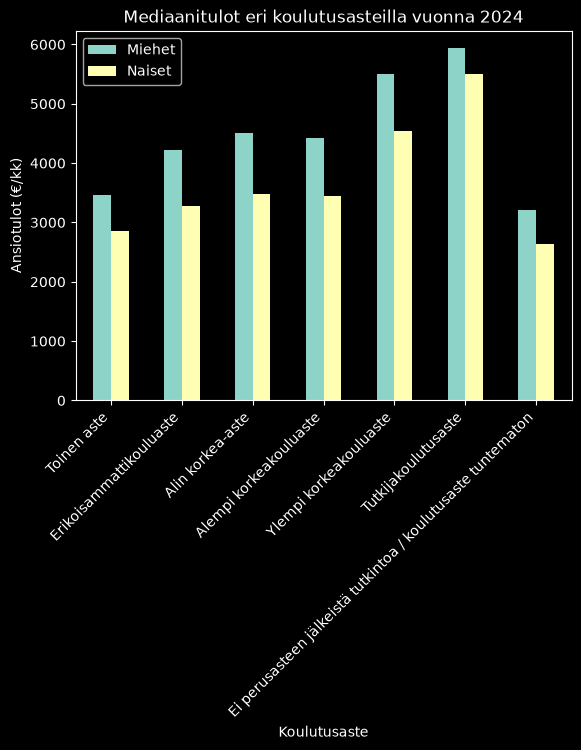

In [4]:
palkkatiedot.plot(
        x= "Koulutusaste",
        y= ["Miehet_euroa_kk", "Naiset_euroa_kk"],
        kind="bar",
)

plt.title("Mediaanitulot eri koulutusasteilla vuonna 2024")
plt.xlabel("Koulutusaste")
plt.ylabel("Ansiotulot (€/kk)")
plt.xticks(rotation=45, ha="right")
plt.legend(["Miehet", "Naiset"])
plt.show()

Edellisestä taulukosta prosenttierot miesten ja naisten mediaanitulojen välillä

Eli kuinka monta prosenttia naisten mediaanitulot ovat pienemmät kuin miesten. (Itse opeteltu ja testattu taulukko)

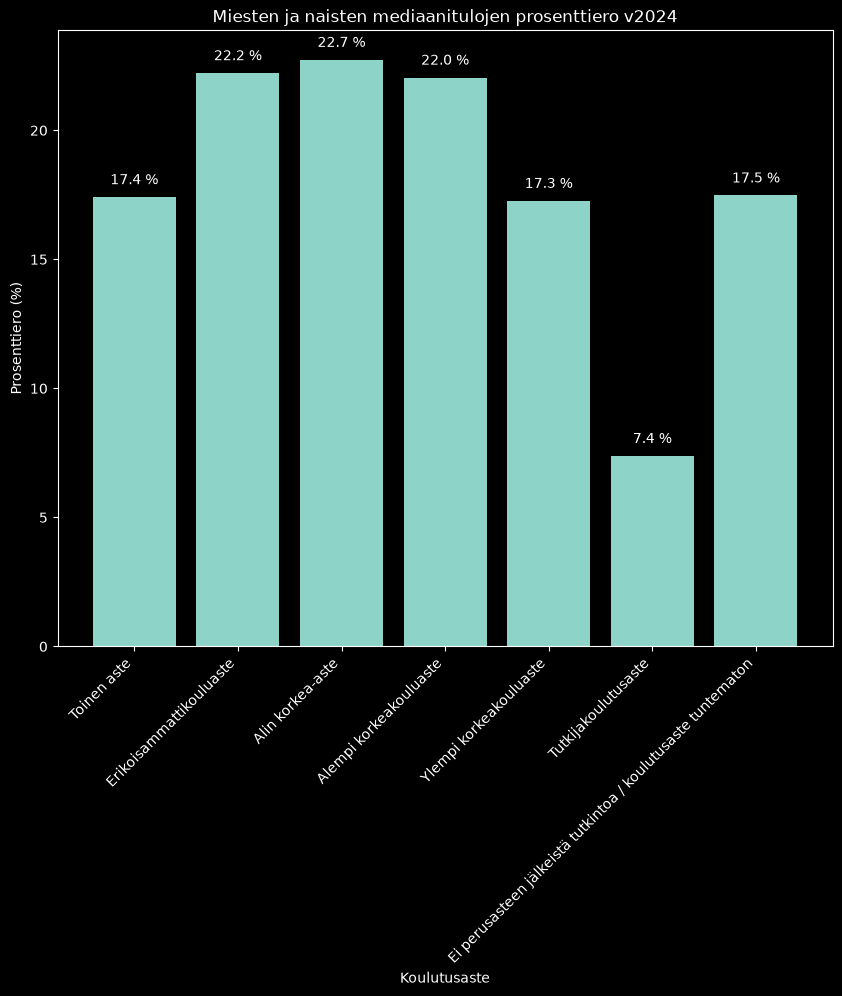

In [5]:
prosenttierot = (
(palkkatiedot["Miehet_euroa_kk"]-palkkatiedot["Naiset_euroa_kk"]) / palkkatiedot["Miehet_euroa_kk"] * 100
)
plt.figure(figsize = (10,8))

plt.bar(palkkatiedot["Koulutusaste"], prosenttierot)

plt.title("Miesten ja naisten mediaanitulojen prosenttiero v2024")
plt.xlabel("Koulutusaste")
plt.ylabel("Prosenttiero (%)")
plt.xticks(rotation=45, ha="right")

for i, arvo in enumerate(prosenttierot):
    plt.text(i, arvo + 0.5, f"{arvo:.1f} %", ha="center")
plt.show()

2. Keskitulojen vertailu koulutusaloittain vuonna 2024

In [6]:
keskitulot = pd.read_excel("t8_tilastokeskus.xlsx", sheet_name="Keskitulot")

keskitulot.head()

,Koulutusala,Alempi_korkeakouluaste_euroa_kk,Ylempi_korkeakouluaste_euroa_kk,Tutkijakoulutuaste_euroa_kk,Kolmen_koulutusasteen_keskiarvo_euroa_kk
0,Yleissivistävä koulutus,NaN,NaN,NaN,NaN
1,Kasvatusalat,3416.0,4415.0,5453.0,4428.0
2,Humanistiset ja taidealat,3629.0,4340.0,5188.0,4386.0
3,Yhteiskunnalliset alat,3886.0,5120.0,5970.0,4992.0
4,"Kauppa, hallinto ja oikeustieteet",4160.0,6289.0,6866.0,5772.0


In [7]:
keskitulot.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Koulutusala                               12 non-null     str    
 1   Alempi_korkeakouluaste_euroa_kk           11 non-null     float64
 2   Ylempi_korkeakouluaste_euroa_kk           11 non-null     float64
 3   Tutkijakoulutuaste_euroa_kk               11 non-null     float64
 4   Kolmen_koulutusasteen_keskiarvo_euroa_kk  11 non-null     float64
dtypes: float64(4), str(1)
memory usage: 612.0 bytes


Tarkastelen koulutusalojen kolmen korkeimman koulutusasteen keskimääräisiä ansioita

In [8]:
keskitulot[["Koulutusala", "Kolmen_koulutusasteen_keskiarvo_euroa_kk"]]

,Koulutusala,Kolmen_koulutusasteen_keskiarvo_euroa_kk
0,Yleissivistävä koulutus,NaN
1,Kasvatusalat,4428.0
2,Humanistiset ja taidealat,4386.0
3,Yhteiskunnalliset alat,4992.0
4,"Kauppa, hallinto ja oikeustieteet",5772.0
5,Luonnontieteet,4693.0
6,Tietojenkäsittely ja tietoliikenne (ICT),5786.0
7,Tekniikan alat,5836.0
8,Maa- ja metsätalousalat,5038.0
9,Terveys- ja hyvinvointialat,5957.0


Koulutusalojen keskimääräiset ansiot vuonna 2024

Lisätty keskiarvot pylväiden päälle extrana (mallina aiemman tehtävän prosentit)

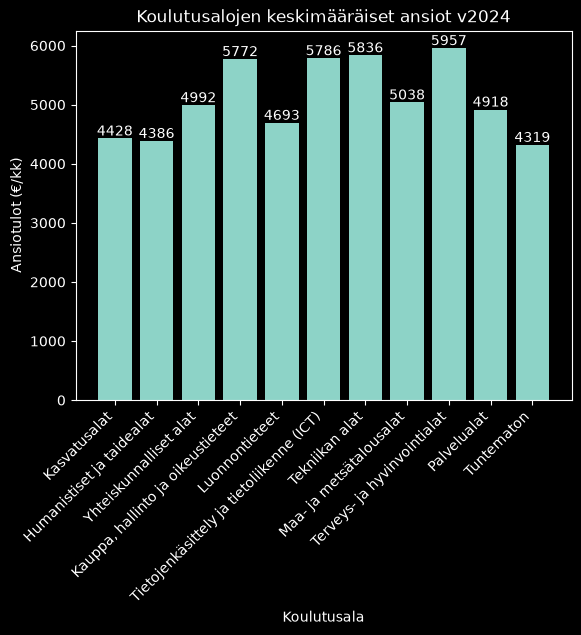

In [9]:
plt.bar(
    keskitulot["Koulutusala"],
    keskitulot["Kolmen_koulutusasteen_keskiarvo_euroa_kk"],
)

plt.title("Koulutusalojen keskimääräiset ansiot v2024")
plt.xlabel("Koulutusala")
plt.ylabel("Ansiotulot (€/kk)")
plt.xticks(rotation=45, ha="right")

for i, arvo in enumerate(keskitulot["Kolmen_koulutusasteen_keskiarvo_euroa_kk"]):
    plt.text(i, arvo + 50, f"{arvo:.0f}", ha="center")

plt.show()

Järjestän koulutusalat tulojen mukaan suurimmasta pienempään vertailua helpottamaan

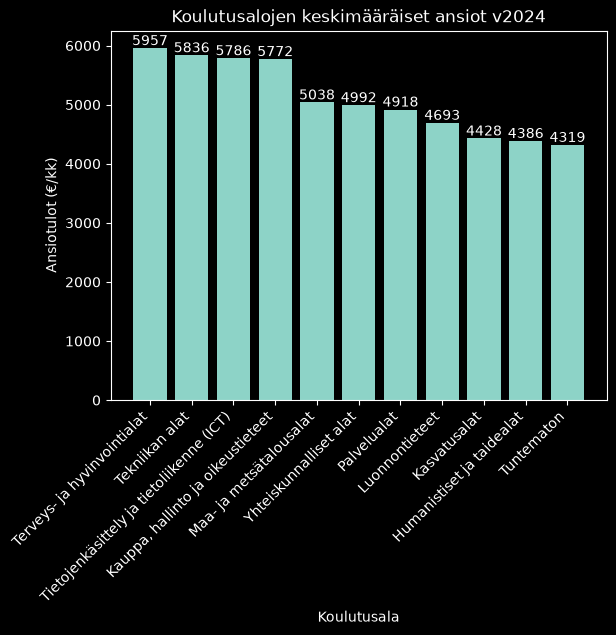

In [10]:
keskitulot_järjestetty = keskitulot.sort_values(
    by="Kolmen_koulutusasteen_keskiarvo_euroa_kk",
    ascending=False
)

plt.bar(
    keskitulot_järjestetty["Koulutusala"],
    keskitulot_järjestetty["Kolmen_koulutusasteen_keskiarvo_euroa_kk"],
)

plt.title("Koulutusalojen keskimääräiset ansiot v2024")
plt.xlabel("Koulutusala")
plt.ylabel("Ansiotulot (€/kk)")
plt.xticks(rotation=45, ha="right")

for i, arvo in enumerate(keskitulot_järjestetty["Kolmen_koulutusasteen_keskiarvo_euroa_kk"]):
    plt.text(i, arvo + 50, f"{arvo:.0f}", ha="center")

plt.show()

Koulutusaloista korkeimmat keskimääräiset ansiot on terveys- ja hyvinvointialoilla, tekniikan aloilla sekä ICT-alalla. Matalimmat keskiansiot ovat humanistisilla ja taidealoilla sekä kasvatusaloilla. Tuntemattoman koulutusalan keskiarvo on näitäkin pienempi.